# Deep Learning, Phase 1, Day 5: Regularization and a Multi-class Classifier
1. Overfitting and underfitting  2. A model that overfits  3. Dropout  4. Weight decay (L2)  5. Early stopping  6. Choose with validation, test once  7. Multi-class classifier on Iris

In [12]:
import copy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, ConfusionMatrixDisplay
sns.set_theme(style='whitegrid')

## 1. Overfitting and underfitting
- **Underfitting:** the model is too simple or trained too little. Both train and validation loss are high.
- **Overfitting:** the model memorises the training data, including its noise. Train loss keeps falling, but **validation loss stops falling or rises**.
- **Regularization** = anything that discourages overfitting. Three tools today: **dropout**, **weight decay** and **early stopping**.

We use the same Breast Cancer data and splits as Day 4 (train 340, validation 86, test 143).

In [13]:
data = load_breast_cancer(as_frame=True); X, y = data.data, data.target
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
X_tr, X_val, y_tr, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full)
scaler = StandardScaler().fit(X_tr)                                   # fitted on training data only
to_t = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
Xtr, Xval, Xte = (to_t(scaler.transform(a)) for a in (X_tr, X_val, X_test))
ytr, yval, yte = (to_t(v).unsqueeze(1) for v in (y_tr, y_val, y_test))
loss_fn = nn.BCEWithLogitsLoss()

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        lg = model(X); return loss_fn(lg, y).item(), ((lg > 0).float() == y).float().mean().item()

def make_model(hidden=(128, 64), dropout=0.0, seed=0):
    torch.manual_seed(seed); layers, n_in = [], 30
    for h in hidden:
        layers += [nn.Linear(n_in, h), nn.ReLU()] + ([nn.Dropout(dropout)] if dropout > 0 else []); n_in = h
    return nn.Sequential(*layers, nn.Linear(n_in, 1))

def train(model, epochs=200, lr=1e-3, weight_decay=0.0, patience=None, batch_size=32, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True)
    hist = {'loss': [], 'val_loss': [], 'acc': [], 'val_acc': []}
    best, best_state, best_ep, wait = float('inf'), None, 0, 0
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            opt.zero_grad(); loss_fn(model(xb), yb).backward(); opt.step()
        l, a = evaluate(model, Xtr, ytr); vl, va = evaluate(model, Xval, yval)
        for k, v in zip(hist, (l, vl, a, va)): hist[k].append(v)
        if vl < best - 1e-4: best, best_state, best_ep, wait = vl, copy.deepcopy(model.state_dict()), ep + 1, 0
        else: wait += 1
        if patience and wait >= patience: break                       # early stopping
    if patience and best_state is not None: model.load_state_dict(best_state)   # go back to the best epoch
    hist['best_epoch'] = best_ep; hist['stopped_at'] = len(hist['loss'])
    return hist

## 2. Underfitting and overfitting, side by side
- **Underfit:** a normal model trained for only 3 epochs with a tiny learning rate.
- **Overfit:** a big model (30 -> 128 -> 64 -> 1) trained for 200 epochs with no regularization.

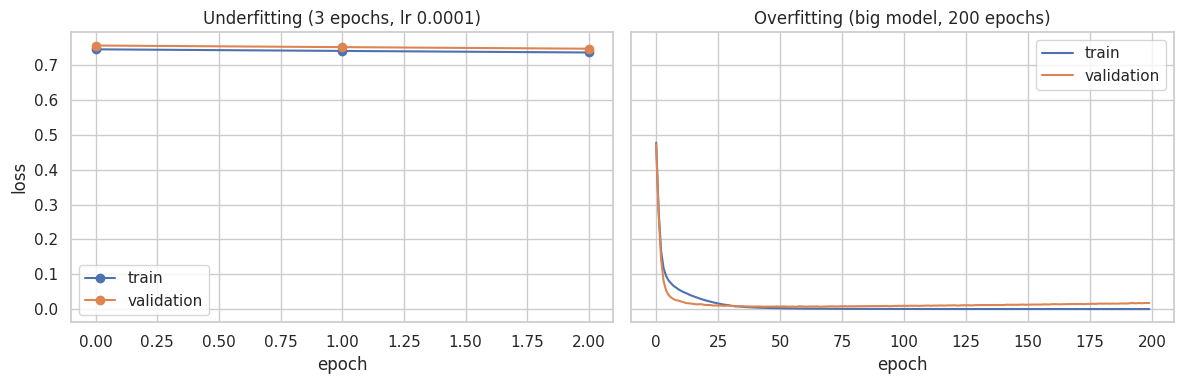

Overfit model: lowest validation loss 0.0067 at epoch 57, validation loss at the end 0.0175, train loss at the end 0.00006


In [14]:
m_under = make_model(hidden=(8,)); h_under = train(m_under, epochs=3, lr=1e-4)
m_over  = make_model(hidden=(128, 64)); h_over = train(m_over, epochs=200)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax[0].plot(h_under['loss'], 'o-', label='train'); ax[0].plot(h_under['val_loss'], 'o-', label='validation'); ax[0].set(title='Underfitting (3 epochs, lr 0.0001)', xlabel='epoch', ylabel='loss'); ax[0].legend()
ax[1].plot(h_over['loss'], label='train'); ax[1].plot(h_over['val_loss'], label='validation'); ax[1].set(title='Overfitting (big model, 200 epochs)', xlabel='epoch'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Overfit model: lowest validation loss {min(h_over['val_loss']):.4f} at epoch {int(np.argmin(h_over['val_loss'])) + 1}, validation loss at the end {h_over['val_loss'][-1]:.4f}, train loss at the end {h_over['loss'][-1]:.5f}")

## 3. Dropout
During training, **dropout** randomly switches off a fraction of the neurons in each step (here 30%). The network cannot rely on any single neuron, so it learns more robust patterns. At prediction time (`model.eval()`) dropout is turned off automatically. That is why we call `model.train()` and `model.eval()`.

In [15]:
m_drop = make_model(hidden=(128, 64), dropout=0.3); h_drop = train(m_drop, epochs=200)

## 4. Weight decay (L2 regularization)
Weight decay adds a small penalty on large weights, pushing them towards 0, so the model stays simpler and smoother. In PyTorch it is one argument: `weight_decay=...` in the optimizer.

In [16]:
m_wd = make_model(hidden=(128, 64)); h_wd = train(m_wd, epochs=200, weight_decay=1e-2)

## 5. Early stopping
Watch the **validation loss**. If it has not improved for `patience` epochs, stop training and go back to the weights of the best epoch. It costs nothing and also saves time.

In [17]:
m_es = make_model(hidden=(128, 64)); h_es = train(m_es, epochs=200, patience=15)
print(f"Early stopping: best epoch {h_es['best_epoch']}, training stopped at epoch {h_es['stopped_at']} (of a maximum of 200)")

Early stopping: best epoch 57, training stopped at epoch 72 (of a maximum of 200)


**Combined:** dropout + weight decay + early stopping.

Combined: best epoch 54, stopped at epoch 69


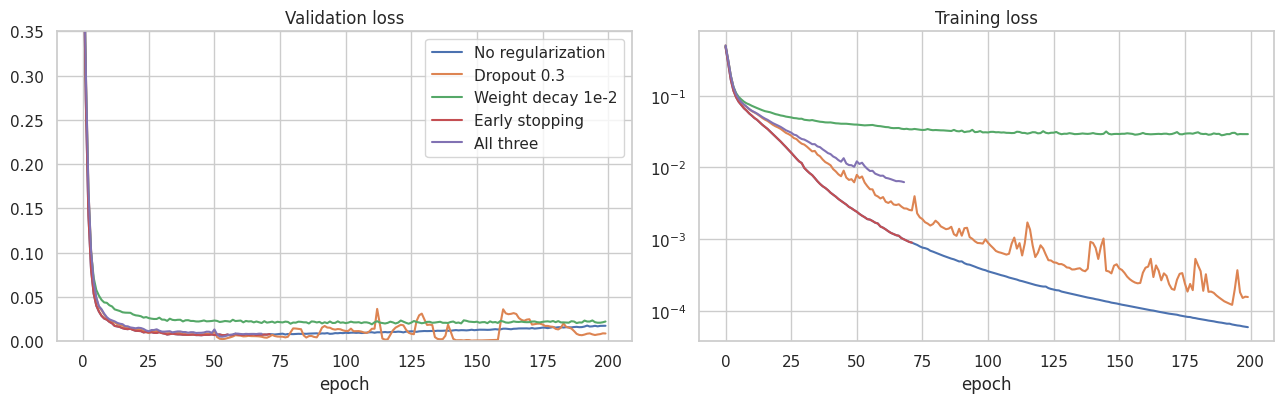

In [18]:
m_all = make_model(hidden=(128, 64), dropout=0.3); h_all = train(m_all, epochs=200, weight_decay=1e-3, patience=15)
print(f"Combined: best epoch {h_all['best_epoch']}, stopped at epoch {h_all['stopped_at']}")

runs = {'No regularization': h_over, 'Dropout 0.3': h_drop, 'Weight decay 1e-2': h_wd, 'Early stopping': h_es, 'All three': h_all}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for n, h in runs.items():
    ax[0].plot(h['val_loss'], label=n); ax[1].plot(h['loss'], label=n)
ax[0].set(title='Validation loss', xlabel='epoch', ylim=(0, 0.35)); ax[1].set(title='Training loss', xlabel='epoch', yscale='log'); ax[0].legend()
plt.tight_layout(); plt.show()

## 6. Compare on validation data, then use the test set once
We compare the variants on the **validation** set (that is what the validation set is for). The model with the lowest validation loss is our choice, and **only that one** is scored on the test set.

In [19]:
models = {'No regularization': m_over, 'Dropout 0.3': m_drop, 'Weight decay 1e-2': m_wd, 'Early stopping': m_es, 'All three': m_all}
tbl = pd.DataFrame({n: {'epochs run': runs[n].get('stopped_at', 200), 'val loss': evaluate(m, Xval, yval)[0], 'val acc': evaluate(m, Xval, yval)[1],
                        'train loss': evaluate(m, Xtr, ytr)[0], 'gap (val - train loss)': evaluate(m, Xval, yval)[0] - evaluate(m, Xtr, ytr)[0]} for n, m in models.items()}).T.round(4)
display(tbl)
chosen = tbl['val loss'].astype(float).idxmin(); print('Chosen by validation loss:', chosen)

,epochs run,val loss,val acc,train loss,gap (val - train loss)
No regularization,200.0,0.0175,0.9767,0.0001,0.0174
Dropout 0.3,200.0,0.0088,0.9884,0.0002,0.0086
Weight decay 1e-2,200.0,0.0223,1.0000,0.0292,-0.0069
Early stopping,72.0,0.0067,1.0000,0.0018,0.0049
All three,69.0,0.0051,1.0000,0.0104,-0.0053


Chosen by validation loss: All three


In [20]:
m = models[chosen]; m.eval()
with torch.no_grad(): pred = (m(Xte) > 0).int().ravel().numpy()
print(f'TEST (used once): accuracy {accuracy_score(y_test, pred):.3f} | malignant recall {recall_score(y_test, pred, pos_label=0):.3f}')
print('Day 4 model, for reference (my run): accuracy 0.965, malignant recall 0.981')

TEST (used once): accuracy 0.965 | malignant recall 0.981
Day 4 model, for reference (my run): accuracy 0.965, malignant recall 0.981


## 7. Multi-class classifier on Iris
Three classes (setosa, versicolor, virginica), 4 features. What changes compared with the binary model:
- The output layer has **3 neurons** (one score per class).
- Loss: `CrossEntropyLoss`. It applies **softmax** internally, so the model outputs raw logits again, and the targets are **class numbers** (0, 1, 2), not 0/1 floats.
- Prediction: the class with the largest logit (`argmax`).

Iris has only 150 rows, so the splits are small: 90 train, 30 validation, 30 test.

Train / val / test: 90 30 30


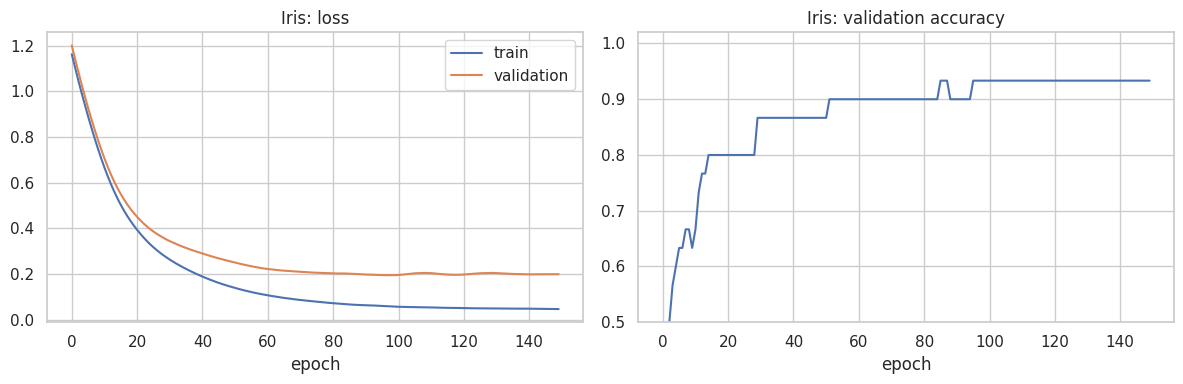

In [21]:
iris = load_iris(); Xi, yi = iris.data, iris.target
Xi_tv, Xi_te, yi_tv, yi_te = train_test_split(Xi, yi, test_size=0.2, random_state=42, stratify=yi)
Xi_tr, Xi_va, yi_tr, yi_va = train_test_split(Xi_tv, yi_tv, test_size=0.25, random_state=42, stratify=yi_tv)
sc = StandardScaler().fit(Xi_tr)
T = lambda a: torch.tensor(sc.transform(a), dtype=torch.float32); L = lambda a: torch.tensor(a, dtype=torch.long)
Xi_tr_t, Xi_va_t, Xi_te_t = T(Xi_tr), T(Xi_va), T(Xi_te); yi_tr_t, yi_va_t, yi_te_t = L(yi_tr), L(yi_va), L(yi_te)
print('Train / val / test:', len(Xi_tr), len(Xi_va), len(Xi_te))

ce = nn.CrossEntropyLoss()
torch.manual_seed(0)
iris_model = nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Dropout(0.1), nn.Linear(16, 3))
opt = torch.optim.Adam(iris_model.parameters(), lr=0.01, weight_decay=1e-3)
hi = {'loss': [], 'val_loss': [], 'val_acc': []}
for ep in range(150):
    iris_model.train(); opt.zero_grad(); ce(iris_model(Xi_tr_t), yi_tr_t).backward(); opt.step()     # full batch
    iris_model.eval()
    with torch.no_grad():
        hi['loss'].append(ce(iris_model(Xi_tr_t), yi_tr_t).item()); lv = iris_model(Xi_va_t)
        hi['val_loss'].append(ce(lv, yi_va_t).item()); hi['val_acc'].append((lv.argmax(1) == yi_va_t).float().mean().item())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hi['loss'], label='train'); ax[0].plot(hi['val_loss'], label='validation'); ax[0].set(title='Iris: loss', xlabel='epoch'); ax[0].legend()
ax[1].plot(hi['val_acc']); ax[1].set(title='Iris: validation accuracy', xlabel='epoch', ylim=(0.5, 1.02)); plt.tight_layout(); plt.show()

Iris TEST accuracy: 0.933 (30 flowers, so one flower = 0.033)


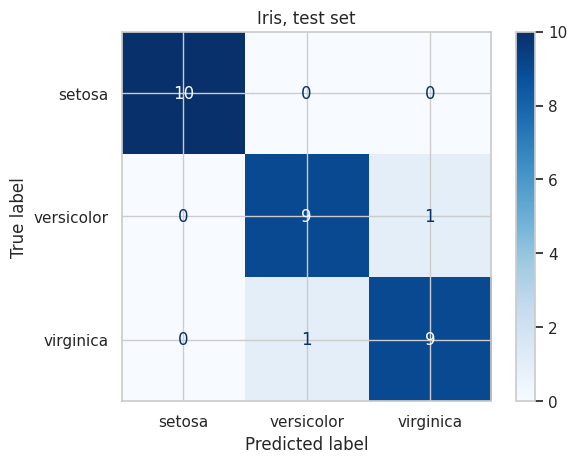

Softmax probabilities of the first 3 test flowers (each row sums to 1):
[[1.    0.    0.   ]
 [0.001 0.075 0.924]
 [0.061 0.937 0.001]] | true classes: [0 2 1]


In [22]:
iris_model.eval()
with torch.no_grad(): logits = iris_model(Xi_te_t); pi = logits.argmax(1).numpy(); probs = torch.softmax(logits, dim=1)
print(f'Iris TEST accuracy: {accuracy_score(yi_te, pi):.3f} (30 flowers, so one flower = 0.033)')
ConfusionMatrixDisplay.from_predictions(yi_te, pi, display_labels=iris.target_names, cmap='Blues'); plt.title('Iris, test set'); plt.show()
print('Softmax probabilities of the first 3 test flowers (each row sums to 1):'); print(probs[:3].numpy().round(3), '| true classes:', yi_te[:3])